# Engagement 2 · Duka Electronics H1 2026 Board Report

**Client:** Duka Electronics board (CEO's request)
**Data:** `duka_sales.csv`, 1,000 orders, 1 Jan to 29 Jun 2026, generated by `generate_data.py` (seed 2026)

## Storyboard

### Audience and decision
- **Audience:** the Duka Electronics board. They are not technical, have limited time and will read the report on their phones before the meeting.
- **Decision they own:** where to focus sales and marketing effort in the second half of 2026.

### Big Idea
Duka's first-half revenue of KES 71.8M looks flat from Q1 to Q2, but that hides a shift: Mombasa and Nakuru each lost about a quarter of their sales while Eldoret grew 50%. The second-half effort should go into recovering Mombasa and Nakuru.

### Situation, Complication, Resolution
- **Situation:** Duka Electronics earned KES 71.8M in the first half of 2026, and Nairobi alone contributed 36%.
- **Complication:** revenue peaked in April and fell 15.6% in May, and the flat quarterly total hides big branch differences: Mombasa fell 25% and Nakuru 27% from Q1 to Q2, while Eldoret grew 50%.
- **Resolution:** we recommend a second-half recovery plan for Mombasa and Nakuru, which together lost about KES 3.9M a quarter, while protecting the growth in Nairobi, Kisumu and Eldoret.

### Chart plan

| # | Question | Chart type | Planned insight title (calculated in code) | Part of story |
|---|---|---|---|---|
| 1 | Where does revenue come from? | Sorted horizontal bar by branch | Nairobi generates 36% of all revenue | Situation |
| 2 | Which products drive revenue? | Sorted horizontal bar by product | Laptops generate 58% of all revenue | Situation |
| 3 | How did revenue move over time? | Line by month | Revenue peaked in April and fell 16% the next month | Complication |
| 4 | Which branches changed between Q1 and Q2? | Horizontal bar of % change, Q2 vs Q1, by branch | Nakuru fell 27% and Mombasa fell 25% from Q1 to Q2, while Eldoret grew 50% | Complication and Resolution |

Each title is calculated from the data in code. Every chart has labelled units and a source line. Colour is used with purpose: redberry (#8E0000) for the point of the story, teal (#0BA184) for growth, grey for everything else.

In [1]:
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Fetch and run the generator from the GitHub repo (it creates duka_sales.csv)
!wget -q -O generate_data.py https://raw.githubusercontent.com/erickodiwuor014-max/plp-da-a4-student-eda-and-board-report/main/generate_data.py
%run generate_data.py

# Shared colours and chart style
RED, GREY, TEAL, INK = "#8E0000", "#C7C9D1", "#0BA184", "#333333"
SOURCE = "Source: Duka Electronics sales records, 1 Jan to 29 Jun 2026"

def style(ax, title, source=SOURCE, width=42):
    """Left-aligned bold insight title, no top/right border, source line under the chart."""
    ax.set_title(textwrap.fill(title, width), loc="left", fontweight="bold", fontsize=13, color=INK)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.annotate(source, xy=(0, 0), xycoords="axes fraction", xytext=(0, -42),
                textcoords="offset points", fontsize=8, color="#555555", va="top")

## Data and first inspection

In [2]:
sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"]

print("Shape:", sales.shape)
print("Missing values:", sales.isna().sum().sum())
print("Unique order_id:", sales["order_id"].nunique())
print("Period:", sales["order_date"].min().date(), "to", sales["order_date"].max().date())
print(f"Total revenue: KES {sales['revenue'].sum():,}")
print("\nOrders by branch:\n", sales["branch"].value_counts().to_string())
print("\nChannel mix:\n", sales["channel"].value_counts(normalize=True).round(3).to_string())
sales.head()

Shape: (1000, 8)
Missing values: 0
Unique order_id: 1000
Period: 2026-01-01 to 2026-06-29
Total revenue: KES 71,792,500

Orders by branch:
 branch
Nairobi    376
Mombasa    186
Nakuru     162
Kisumu     159
Eldoret    117

Channel mix:
 channel
In-store       0.579
Online         0.320
Phone order    0.101


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500


**Inspection:** 1,000 orders from 1 January to 29 June 2026, with no missing values and unique order IDs. The data stops one day short of the end of June, so June is slightly understated. Revenue is `quantity × unit_price`, totalling KES 71,792,500. Nairobi takes the most orders (376) and online orders make up about a third of the mix.

## Chart makeover: revenue by product

**Before:** a default Matplotlib bar chart with no styling. **After:** the same data redesigned with the course's design principles.

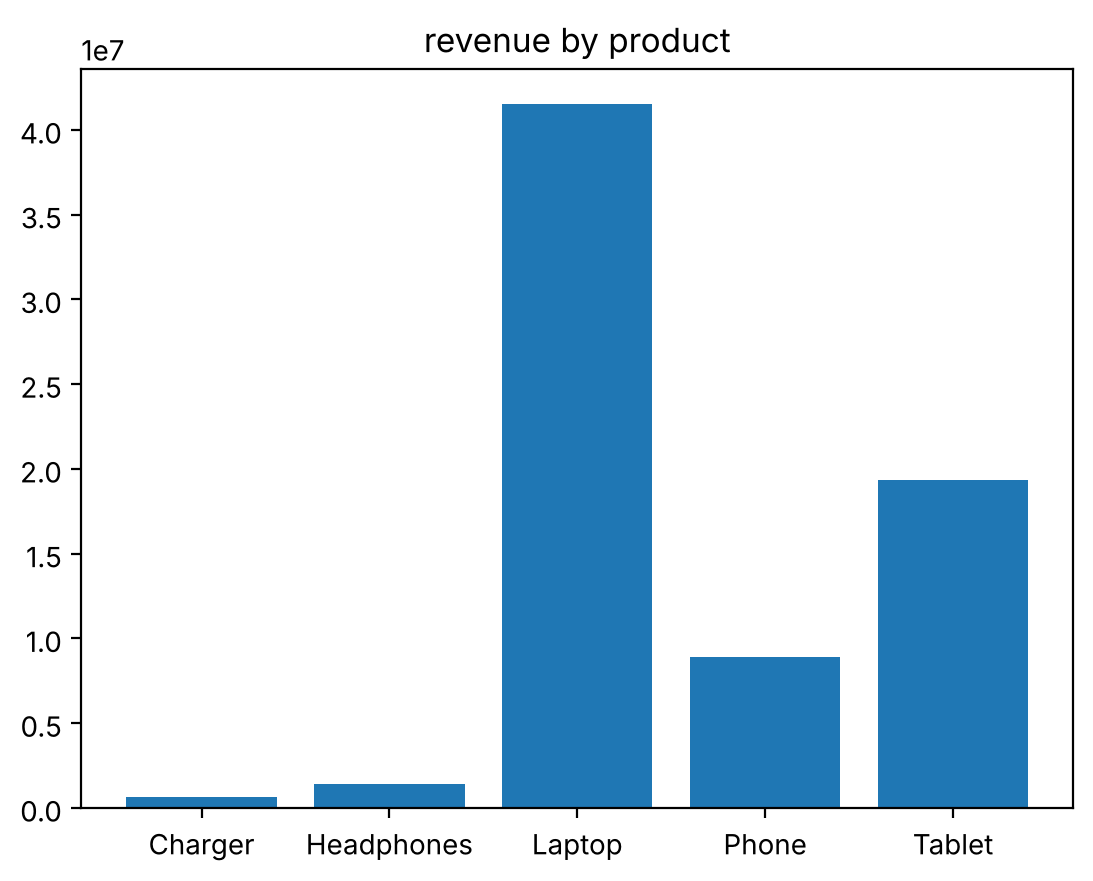

In [3]:
# BEFORE: default chart, deliberately unstyled
product_rev = sales.groupby("product")["revenue"].sum()

fig, ax = plt.subplots()
ax.bar(product_rev.index, product_rev.values)
ax.set_title("revenue by product")
fig.savefig("figures/before.png", dpi=150, bbox_inches="tight")
plt.show()

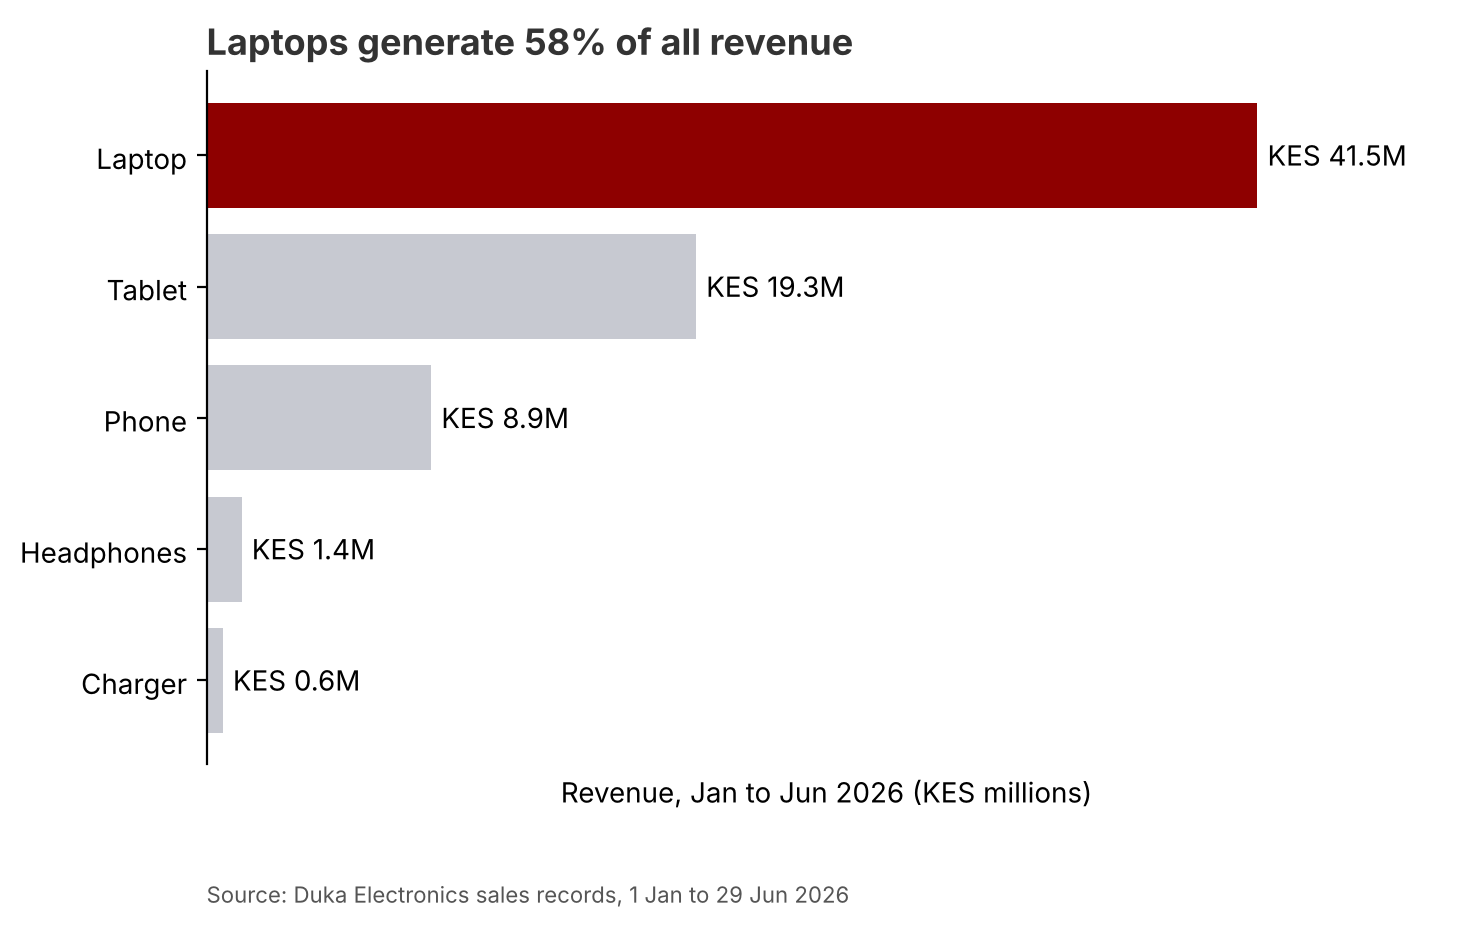

In [4]:
# AFTER: sorted, one highlight colour, direct labels, insight title, units and source
product_rev = sales.groupby("product")["revenue"].sum().sort_values()   # ascending: largest bar on top
top = product_rev.idxmax()
share = product_rev.max() / product_rev.sum()
colors = [RED if p == top else GREY for p in product_rev.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(product_rev.index, product_rev.values, color=colors)
for bar, v in zip(bars, product_rev.values):
    ax.text(v + 400000, bar.get_y() + bar.get_height() / 2, f"KES {v/1e6:.1f}M", va="center")
ax.set_xlim(0, product_rev.max() * 1.18)
ax.set_xticks([])
for side in ["bottom"]:
    ax.spines[side].set_visible(False)
ax.set_xlabel("Revenue, Jan to Jun 2026 (KES millions)")
style(ax, f"{top}s generate {share:.0%} of all revenue")
fig.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.show()

### What changed and why

| Design change | Why it helps the board |
|---|---|
| Bars sorted from largest to smallest | The ranking is visible at a glance, with no hunting for the biggest bar. |
| Horizontal bars | Product names are readable on a phone without rotating text. |
| Grey bars with one redberry bar (#8E0000) | Colour is used with purpose: the eye goes straight to Laptop, the product that carries the message. |
| Direct value labels in KES millions | Readers get the exact numbers, and the axis ticks and gridlines are no longer needed. |
| Top, right and bottom borders removed | Anything that does not help understanding is removed (decluttering). |
| Insight title calculated in code | The title states the conclusion, "Laptops generate 58% of all revenue", instead of a label, and it updates if the data changes. |
| Axis label with units and a source line | The chart can be pasted into WhatsApp or email and still stands alone: units, source and period are visible. |
| Bars start at zero | The bar lengths stay honest and are not exaggerated. |

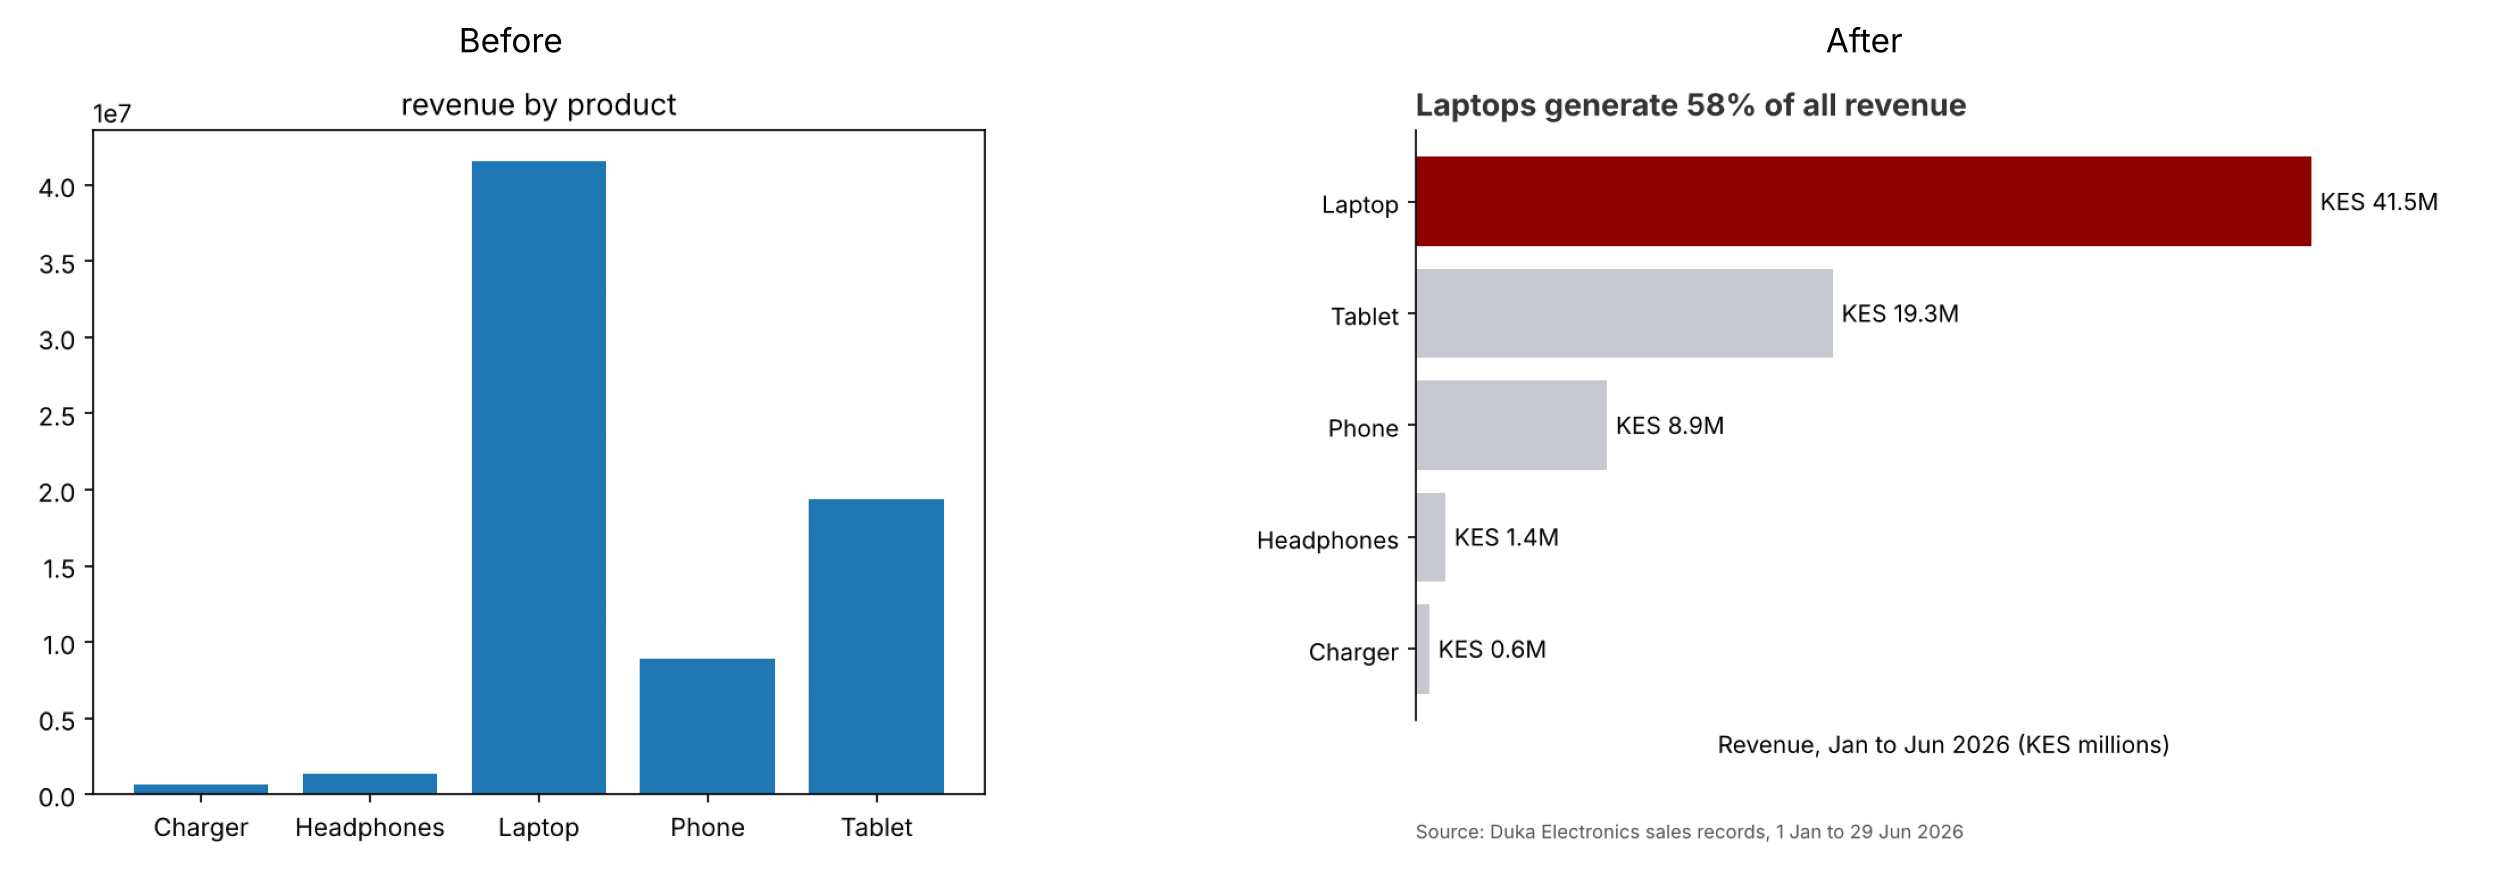

In [5]:
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].imshow(Image.open("figures/before.png")); axes[0].set_title("Before"); axes[0].axis("off")
axes[1].imshow(Image.open("figures/after.png")); axes[1].set_title("After"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## Story charts

One function per chart, so the same code builds each single chart and the one-page report.

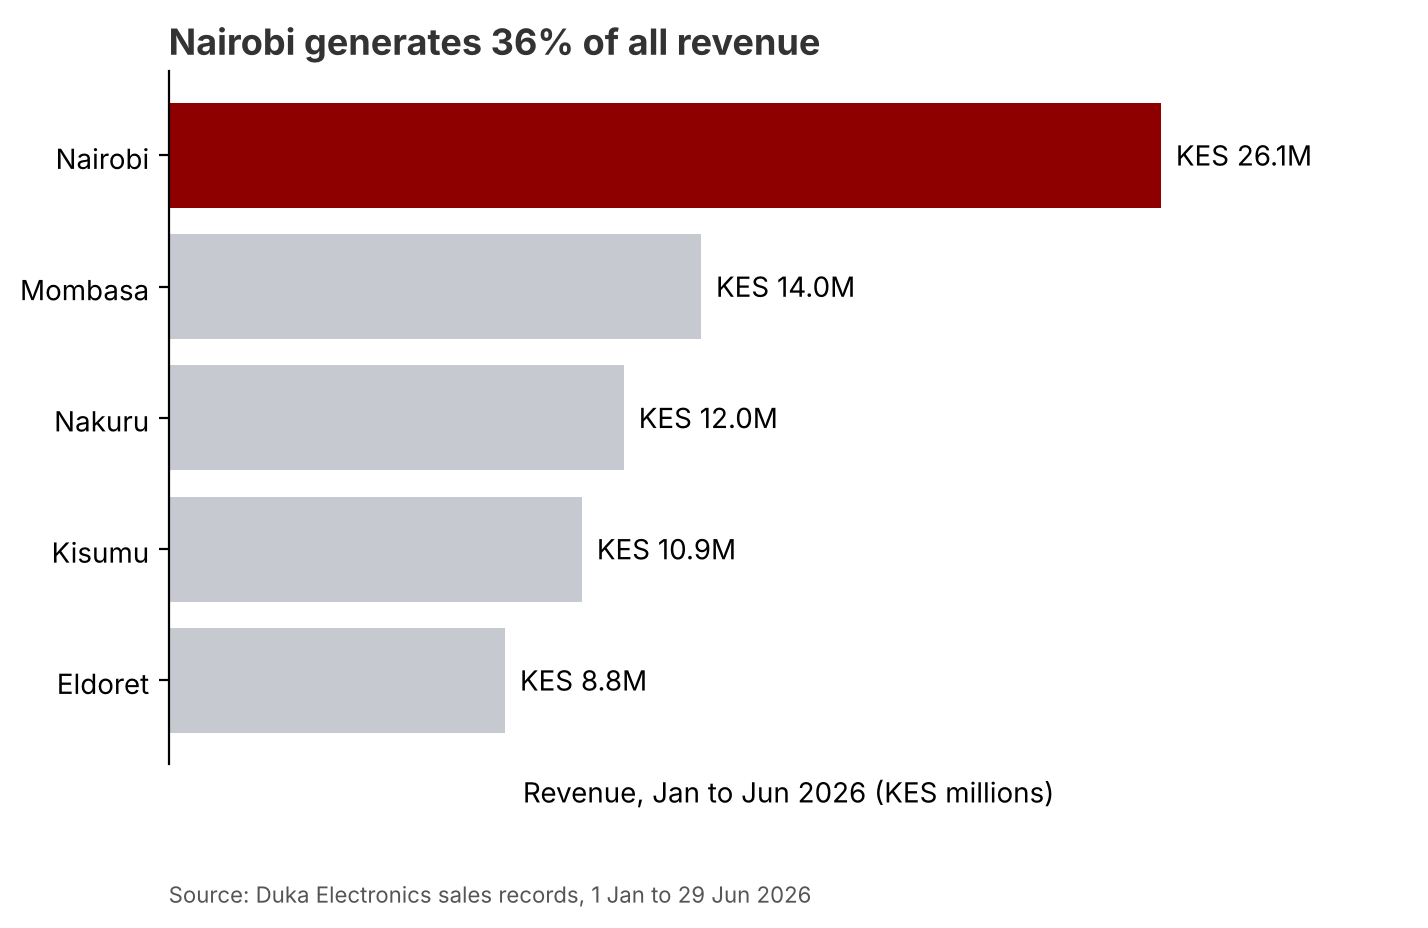

In [6]:
def chart_branch(ax):
    rev = sales.groupby("branch")["revenue"].sum().sort_values()
    top, share = rev.idxmax(), rev.max() / rev.sum()
    colors = [RED if b == top else GREY for b in rev.index]
    bars = ax.barh(rev.index, rev.values, color=colors)
    for bar, v in zip(bars, rev.values):
        ax.text(v + 0.4e6, bar.get_y() + bar.get_height() / 2, f"KES {v/1e6:.1f}M", va="center", fontsize=10)
    ax.set_xlim(0, rev.max() * 1.25)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_xlabel("Revenue, Jan to Jun 2026 (KES millions)")
    style(ax, f"{top} generates {share:.0%} of all revenue")

fig, ax = plt.subplots(figsize=(8, 4.5))
chart_branch(ax)
fig.savefig("figures/duka_01_branch_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

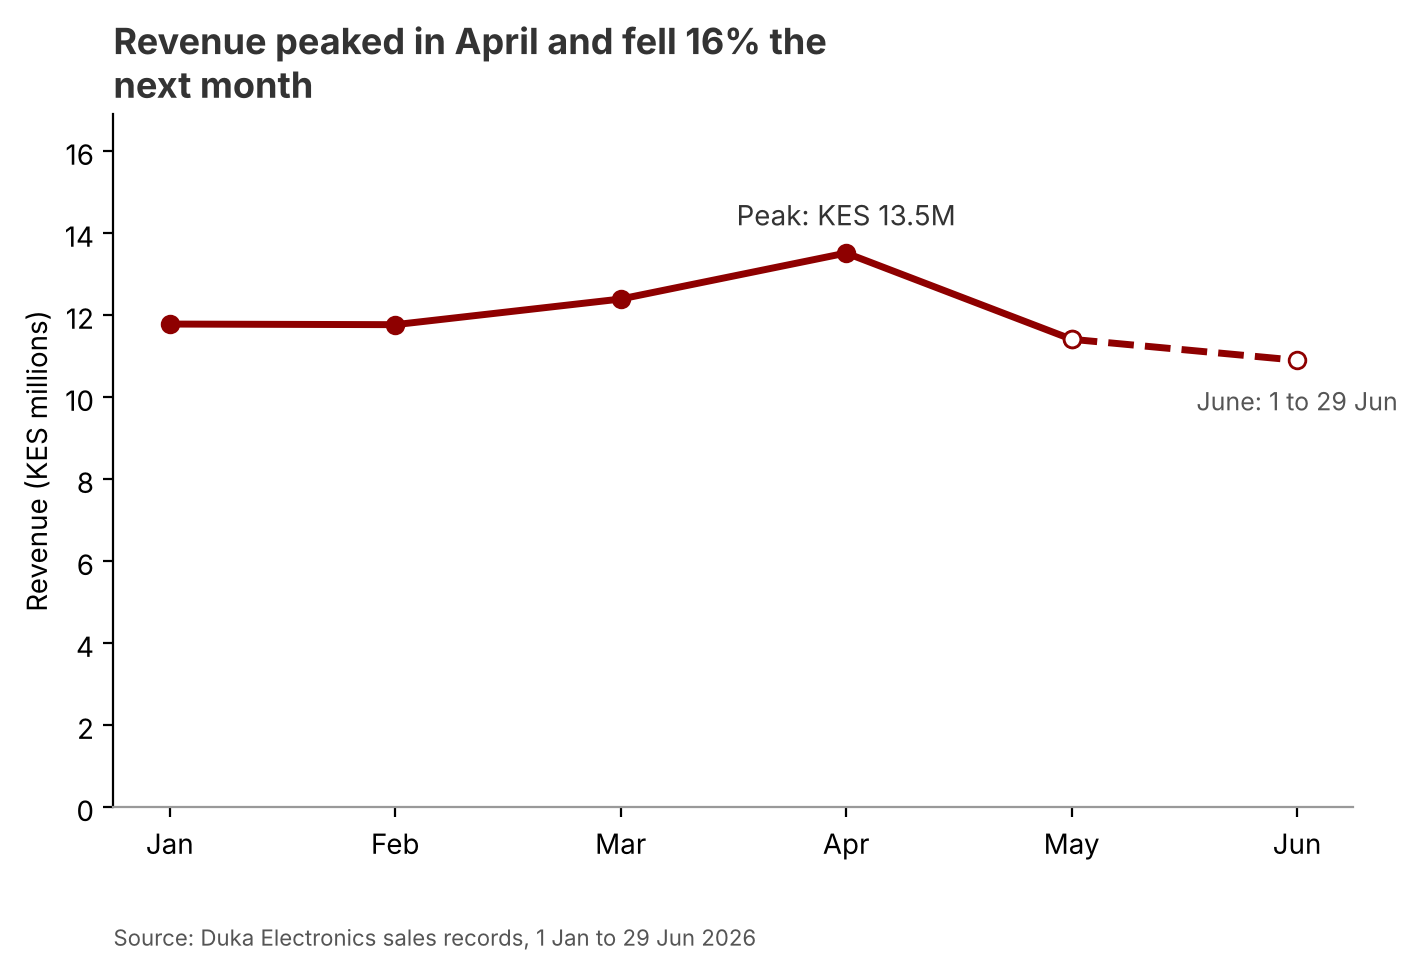

In [7]:
def chart_monthly(ax):
    m = sales.groupby(sales["order_date"].dt.to_period("M"))["revenue"].sum()
    labels = [p.strftime("%b") for p in m.index]
    peak_i = int(np.argmax(m.values))
    peak_name = m.index[peak_i].strftime("%B")
    drop = (m.values[peak_i] - m.values[peak_i + 1]) / m.values[peak_i]   # peak month to the next full month
    x = np.arange(len(m))
    ax.plot(x[:-1], m.values[:-1] / 1e6, color=RED, linewidth=2.5, marker="o")
    ax.plot(x[-2:], m.values[-2:] / 1e6, color=RED, linewidth=2.5, linestyle="--",
            marker="o", markerfacecolor="white")          # dashed: June is incomplete
    ax.annotate(f"Peak: KES {m.values[peak_i]/1e6:.1f}M", (x[peak_i], m.values[peak_i] / 1e6),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=INK)
    ax.annotate("June: 1 to 29 Jun", (x[-1], m.values[-1] / 1e6), textcoords="offset points",
                xytext=(0, -18), ha="center", fontsize=9, color="#555555")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, m.max() / 1e6 * 1.25)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel("Revenue (KES millions)")
    ax.spines["bottom"].set_color("#999999")
    style(ax, f"Revenue peaked in {peak_name} and fell {drop:.0%} the next month")

fig, ax = plt.subplots(figsize=(8, 4.5))
chart_monthly(ax)
fig.savefig("figures/duka_02_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

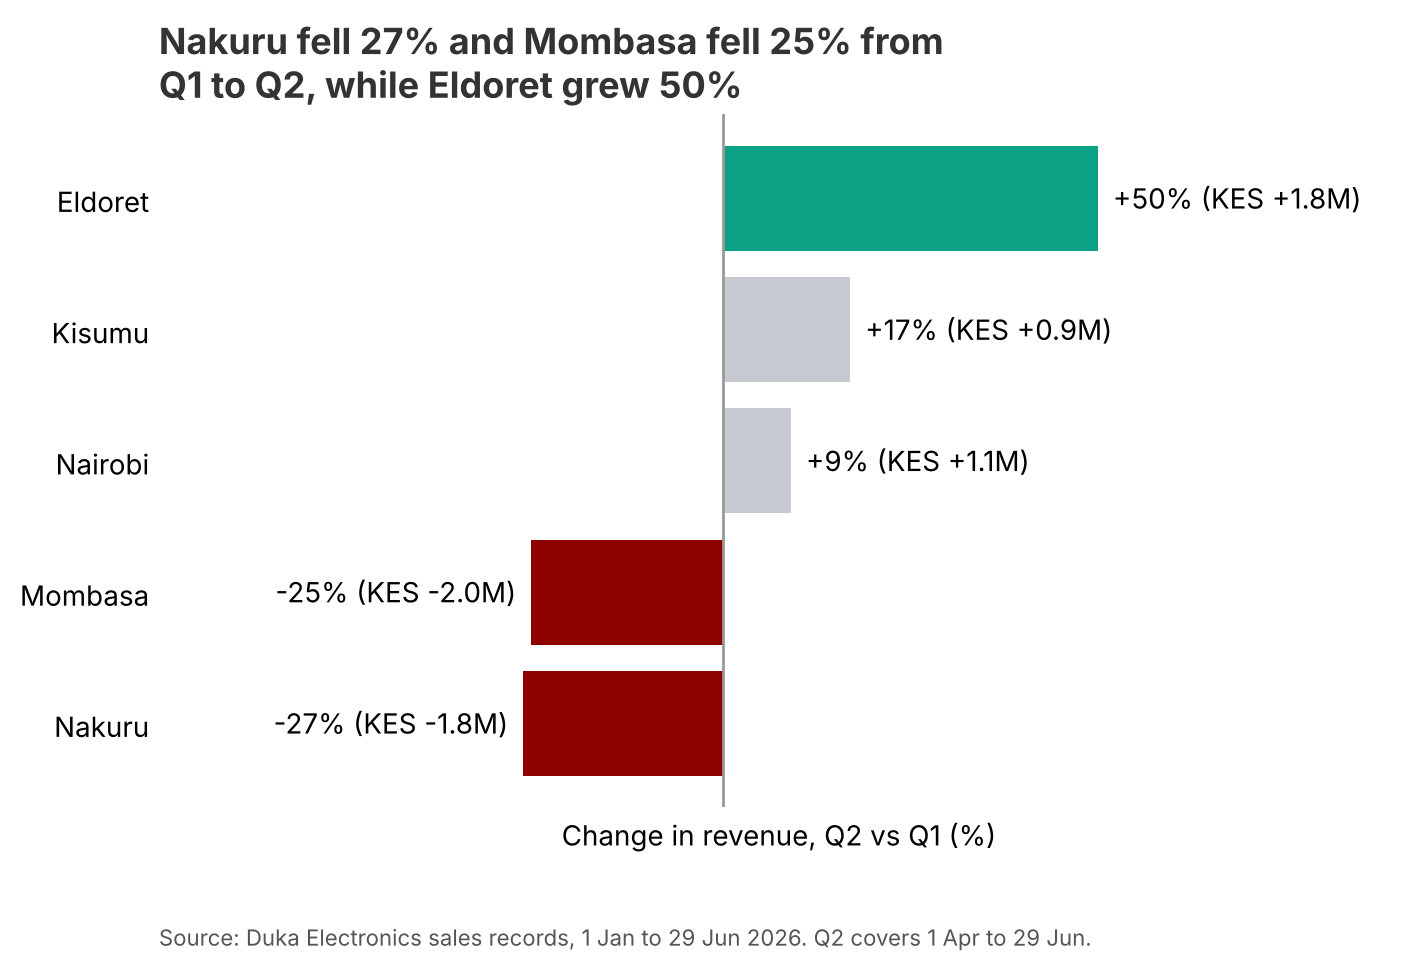

quarter     Q1     Q2
branch               
Eldoret   3.54   5.31
Kisumu    5.01   5.86
Mombasa   8.02   5.98
Nairobi  12.48  13.62
Nakuru    6.90   5.07
branch
Nakuru    -26.5
Mombasa   -25.5
Nairobi     9.1
Kisumu     17.0
Eldoret    49.9
dtype: float64


In [8]:
def chart_q1q2(ax):
    quarter = np.where(sales["order_date"].dt.month <= 3, "Q1", "Q2")
    t = sales.assign(quarter=quarter).pivot_table(index="branch", columns="quarter",
                                                  values="revenue", aggfunc="sum")
    chg = ((t["Q2"] - t["Q1"]) / t["Q1"]).sort_values()
    delta = (t["Q2"] - t["Q1"]).reindex(chg.index)
    worst = chg.index[:2]                                   # the two biggest decliners
    colors = [RED if b in worst else (TEAL if chg[b] == chg.max() else GREY) for b in chg.index]
    bars = ax.barh(chg.index, chg.values * 100, color=colors)
    for bar, b in zip(bars, chg.index):
        v = chg[b] * 100
        ax.text(v + (2 if v >= 0 else -2), bar.get_y() + bar.get_height() / 2,
                f"{chg[b]:+.0%} (KES {delta[b]/1e6:+.1f}M)", va="center",
                ha="left" if v >= 0 else "right", fontsize=10)
    ax.axvline(0, color="#999999", linewidth=1)
    ax.set_xlim(-75, 90)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Change in revenue, Q2 vs Q1 (%)")
    a, b = worst[0], worst[1]
    style(ax, f"{a} fell {-chg[a]:.0%} and {b} fell {-chg[b]:.0%} from Q1 to Q2, "
              f"while {chg.idxmax()} grew {chg.max():.0%}",
          source=SOURCE + ". Q2 covers 1 Apr to 29 Jun.")
    return t, chg

fig, ax = plt.subplots(figsize=(8, 4.5))
q_table, q_change = chart_q1q2(ax)
fig.savefig("figures/duka_03_q1_vs_q2_by_branch.png", dpi=150, bbox_inches="tight")
plt.show()

print((q_table / 1e6).round(2))
print((q_change * 100).round(1))

## One-page board report

**Layout choices for a phone reader:** a single portrait column that scrolls like a phone screen, with the story in order (Situation: where revenue comes from, Complication: what changed, Resolution: the recommendation box). Each chart has an insight title calculated in code, labelled units and a source line. The headline and the recommendation are also calculated from the data.

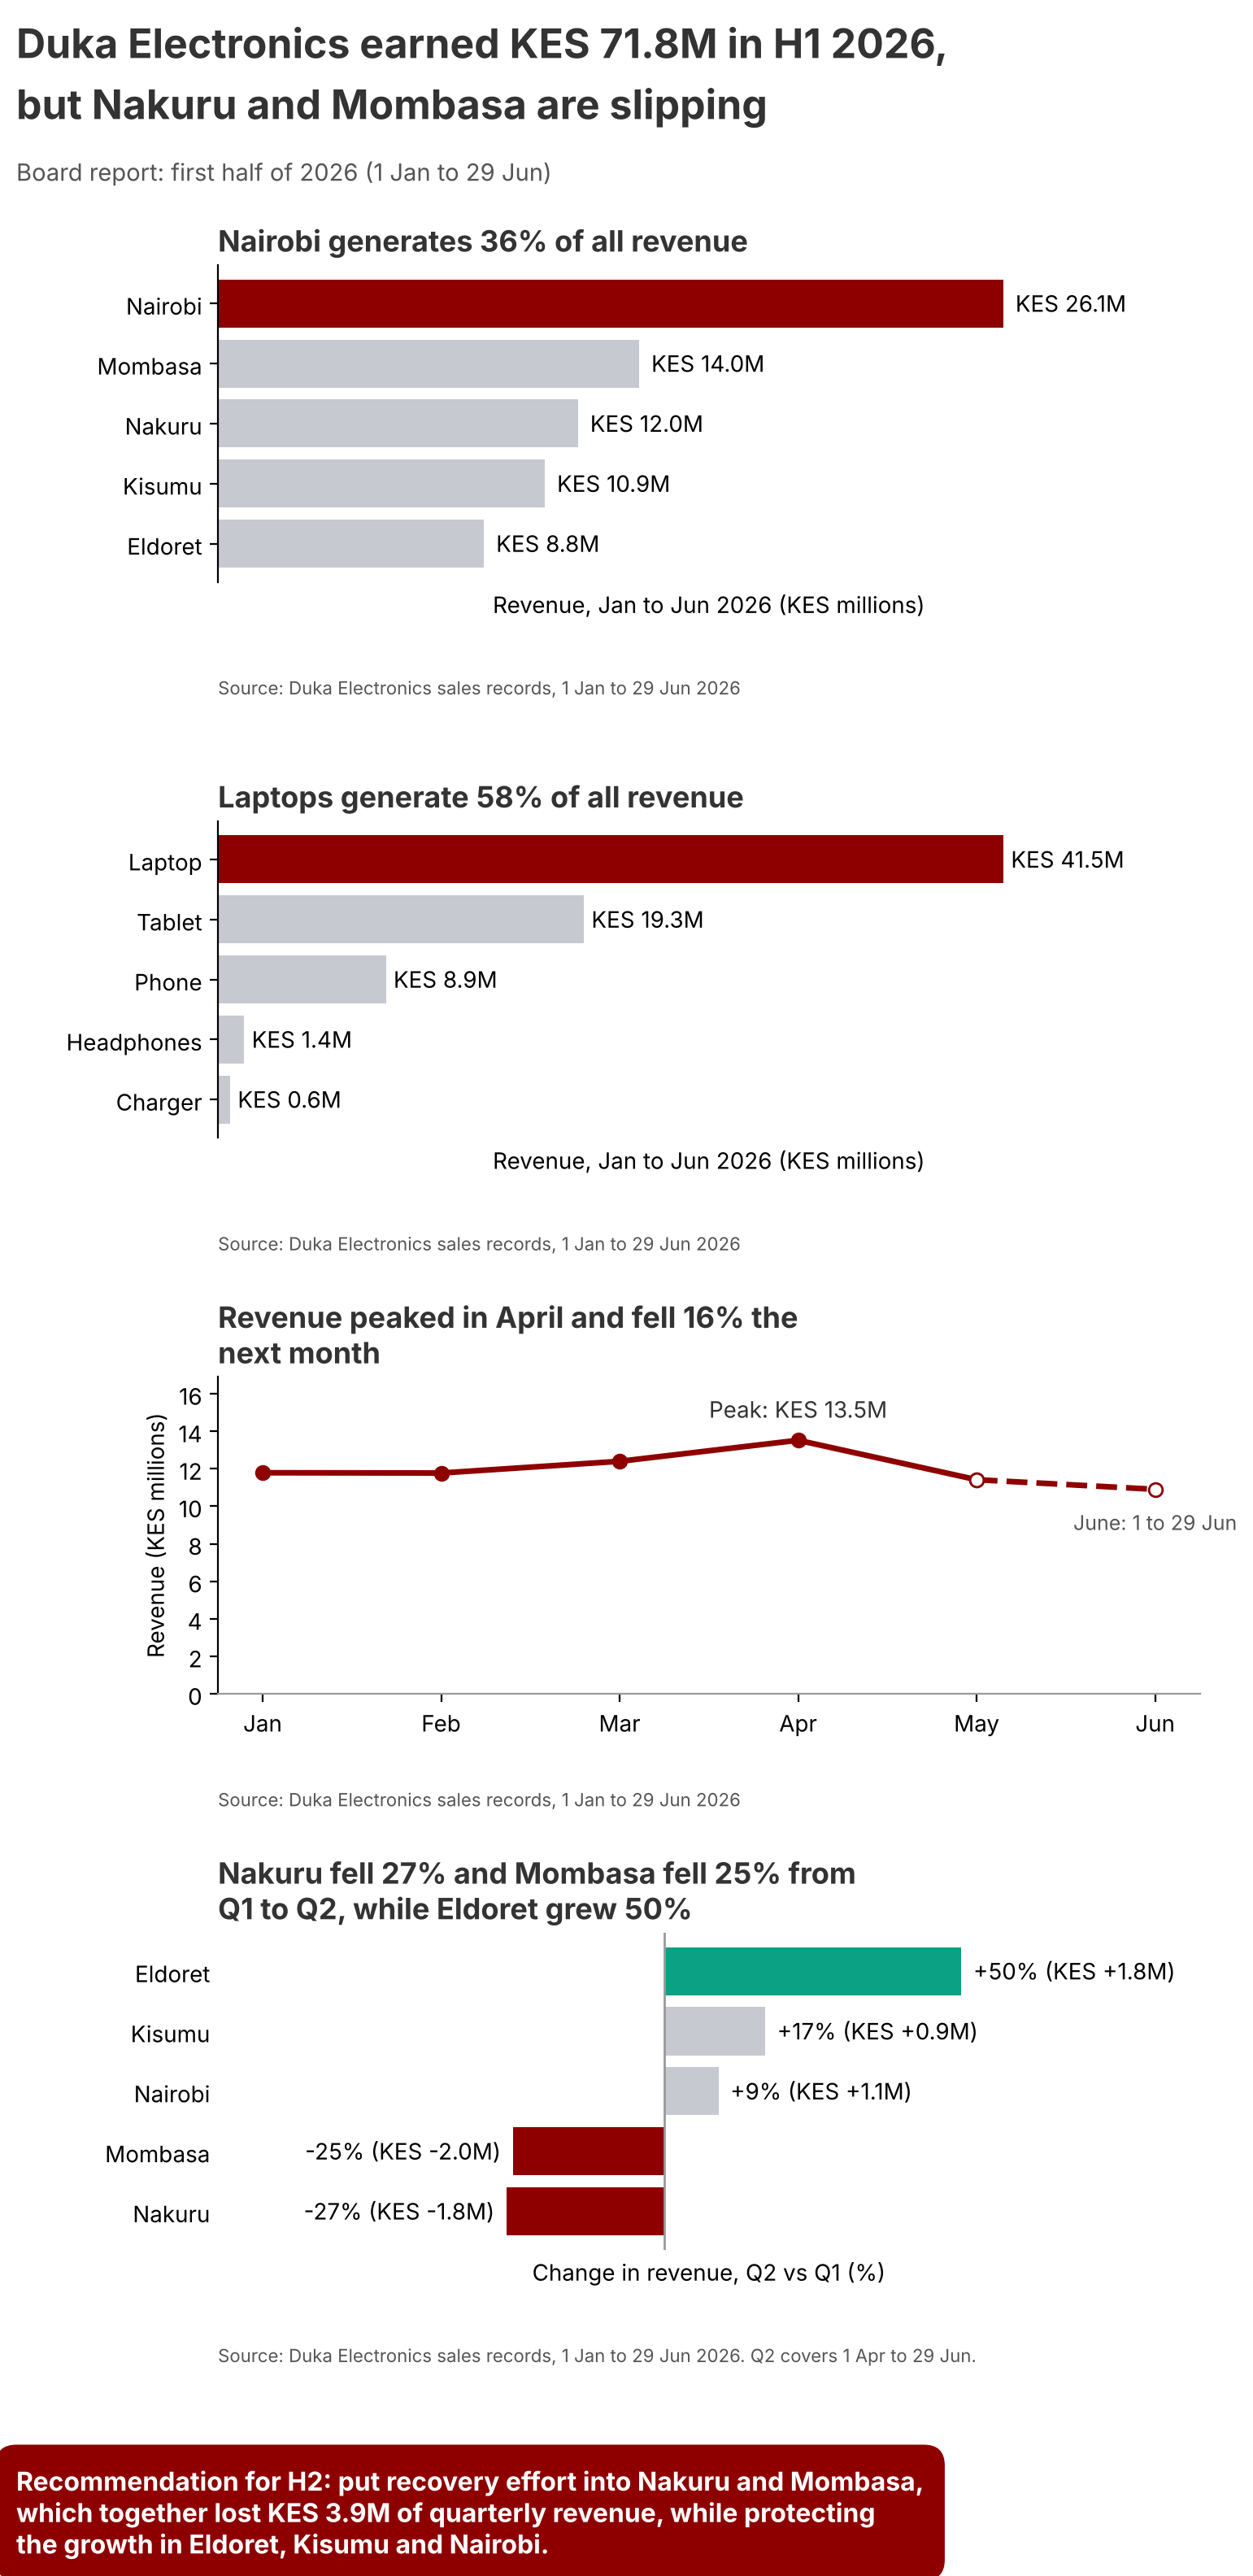

Saved reports/duka_board_report.png (1654, 3300)
figures:
after.png   duka_01_branch_revenue.png	 duka_03_q1_vs_q2_by_branch.png
before.png  duka_02_monthly_revenue.png

reports:
duka_board_report.png


In [9]:
def chart_product(ax):
    rev = sales.groupby("product")["revenue"].sum().sort_values()
    top, share = rev.idxmax(), rev.max() / rev.sum()
    colors = [RED if p == top else GREY for p in rev.index]
    bars = ax.barh(rev.index, rev.values, color=colors)
    for bar, v in zip(bars, rev.values):
        ax.text(v + 0.4e6, bar.get_y() + bar.get_height() / 2, f"KES {v/1e6:.1f}M", va="center", fontsize=10)
    ax.set_xlim(0, rev.max() * 1.25)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_xlabel("Revenue, Jan to Jun 2026 (KES millions)")
    style(ax, f"{top}s generate {share:.0%} of all revenue")

# Numbers for the headline and recommendation, all calculated from the data
total = sales["revenue"].sum()
quarter = np.where(sales["order_date"].dt.month <= 3, "Q1", "Q2")
qt = sales.assign(quarter=quarter).pivot_table(index="branch", columns="quarter",
                                               values="revenue", aggfunc="sum")
change = ((qt["Q2"] - qt["Q1"]) / qt["Q1"]).sort_values()
worst = list(change.index[:2])                                     # two biggest decliners
growers = [b for b in change.index[::-1] if b not in worst]        # the rest, strongest first
lost = -(qt["Q2"] - qt["Q1"])[worst].sum()

fig = plt.figure(figsize=(8.27, 16.5))
fig.text(0.05, 0.988,
         f"Duka Electronics earned KES {total/1e6:.1f}M in H1 2026,\nbut {worst[0]} and {worst[1]} are slipping",
         fontsize=18, fontweight="bold", color=INK, va="top", linespacing=1.25)
fig.text(0.05, 0.935, "Board report: first half of 2026 (1 Jan to 29 Jun)",
         fontsize=10.5, color="#555555", va="top")

gs = fig.add_gridspec(5, 1, height_ratios=[2.3, 2.3, 2.3, 2.3, 1.0],
                      top=0.895, bottom=0.015, left=0.2, right=0.93, hspace=0.85)
for i, chart in enumerate([chart_branch, chart_product, chart_monthly, chart_q1q2]):
    chart(fig.add_subplot(gs[i]))

recommendation = (f"Recommendation for H2: put recovery effort into {worst[0]} and {worst[1]}, which together "
                  f"lost KES {lost/1e6:.1f}M of quarterly revenue, while protecting the growth in "
                  f"{', '.join(growers[:-1])} and {growers[-1]}.")
fig.text(0.05, 0.075, "\n".join(textwrap.wrap(recommendation, 70)), fontsize=11.5, fontweight="bold",
         color="white", va="top", bbox=dict(boxstyle="round,pad=0.8", facecolor=RED, edgecolor="none"))

fig.savefig("reports/duka_board_report.png", dpi=200)
plt.show()

print("Saved reports/duka_board_report.png", Image.open("reports/duka_board_report.png").size)
!ls figures reports

## Dashboard data export

The Looker Studio dashboard reads `duka_dashboard_data.csv`: one row per order, with dates in ISO format (YYYY-MM-DD) so the BI tool recognises the date field.

In [10]:
export = sales.copy()
export["order_date"] = export["order_date"].dt.strftime("%Y-%m-%d")   # ISO dates import cleanly into BI tools
export.to_csv("duka_dashboard_data.csv", index=False)

print(export.shape)
export.head()

(1000, 8)


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500
